## Лабораторная работа №1 | Вариант 5

Выполнил: Мицкевич Артём М8О-311БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
color = np.dtype([('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')])
color

dtype([('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')])

3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
np.seterr(all='ignore')  # Отключает предупреждения о численных ошибках NumPy
np.seterr(all='warn')    # Возвращает обычное поведение

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
vector = np.random.random(10)
np.sort(vector)

array([0.0582155 , 0.48655702, 0.4984533 , 0.51871623, 0.52721291,
       0.53969957, 0.66341018, 0.88854239, 0.91325685, 0.97301733])

5. Создайте read-only массив(неизменяемый)

In [6]:
array = np.arange(5)
array.flags.writeable = False
array

array([0, 1, 2, 3, 4])

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
points = np.random.random((10, 2))
r = np.sqrt(points[:, 0] ** 2 + points[:, 1] ** 2)
theta = np.arctan2(points[:, 1], points[:, 0])
np.column_stack((r, theta))

array([[0.94471588, 0.2236477 ],
       [0.87833376, 0.18395498],
       [0.69826534, 1.3888213 ],
       [0.2019561 , 0.75981596],
       [0.61001508, 0.43324439],
       [0.80591658, 1.01525472],
       [0.75036021, 1.2800092 ],
       [0.25310697, 0.97041665],
       [0.59215131, 1.50860263],
       [0.83996423, 1.13025211]])

7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
grid_x, grid_y = np.meshgrid(np.linspace(0, 1, 5), np.linspace(0, 1, 5))
coords = np.zeros(25, dtype=[('x', 'f8'), ('y', 'f8')])
coords['x'] = grid_x.ravel()
coords['y'] = grid_y.ravel()
coords

array([(0.  , 0.  ), (0.25, 0.  ), (0.5 , 0.  ), (0.75, 0.  ),
       (1.  , 0.  ), (0.  , 0.25), (0.25, 0.25), (0.5 , 0.25),
       (0.75, 0.25), (1.  , 0.25), (0.  , 0.5 ), (0.25, 0.5 ),
       (0.5 , 0.5 ), (0.75, 0.5 ), (1.  , 0.5 ), (0.  , 0.75),
       (0.25, 0.75), (0.5 , 0.75), (0.75, 0.75), (1.  , 0.75),
       (0.  , 1.  ), (0.25, 1.  ), (0.5 , 1.  ), (0.75, 1.  ),
       (1.  , 1.  )], dtype=[('x', '<f8'), ('y', '<f8')])

8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = np.random.normal(size=5)
y = np.random.normal(size=5)
C = 1 / (x[:, None] - y[None, :])
C

array([[ 0.5101173 ,  0.84090195, -1.36061086,  0.76064254,  5.74237933],
       [ 0.79278108,  2.03978342, -0.69739133,  1.62409689, -1.90546121],
       [ 0.29105011,  0.37527673,  1.35037145,  0.35839995,  0.60619109],
       [ 0.5507488 ,  0.95732652, -1.1368964 ,  0.85466114, 33.87508245],
       [ 0.4565773 ,  0.70468416, -1.9798537 ,  0.64743602,  2.47512489]])

9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
values = np.array([1.8, -2.4, 3.1], dtype=np.float32)
values[:] = values.astype(np.int32).view(np.float32)
values.dtype = np.int32
values

array([ 1, -2,  3], dtype=int32)

10. Как случайно заменить p элементов в 2D массиве?

In [11]:
array = np.arange(20).reshape(4, 5)
p = 5
positions = np.random.choice(array.size, p, replace=False)
array.flat[positions] = -1
array

array([[ 0,  1, -1, -1,  4],
       [ 5,  6,  7,  8,  9],
       [-1, 11, 12, 13, 14],
       [15, 16, -1, 18, -1]])

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv('data.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Узнайте сколько было на борту человек

In [14]:
print('Всего пассажиров:', len(df))

Всего пассажиров: 891


2. Какой медианный и средний возраста пассажиров

In [15]:
print('Медианный возраст:', df['Age'].median())
print('Средний возраст:', round(df['Age'].mean(), 2))

Медианный возраст: 28.0
Средний возраст: 29.7


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
known_age = df.dropna(subset=['Age'])
child = known_age['Age'] < 16
print('Дети до 16 лет:', round(known_age.loc[child, 'Survived'].mean() * 100, 1), '%')
print('Взрослые:', round(known_age.loc[~child, 'Survived'].mean() * 100, 1), '%')

Дети до 16 лет: 59.0 %
Взрослые: 38.2 %


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
print('Дети до 16 лет:', round(known_age.loc[child, 'Survived'].mean() * 100, 1), '%')
adult_women = known_age[(known_age['Age'] >= 16) & (known_age['Sex'] == 'female')]
adult_men = known_age[(known_age['Age'] >= 16) & (known_age['Sex'] == 'male')]
print('Женщины от 16 лет:', round(adult_women['Survived'].mean() * 100, 1), '%')
print('Мужчины от 16 лет:', round(adult_men['Survived'].mean() * 100, 1), '%')
print('Женщины и дети выживали чаще взрослых мужчин.')

Дети до 16 лет: 59.0 %
Женщины от 16 лет: 77.5 %
Мужчины от 16 лет: 17.4 %
Женщины и дети выживали чаще взрослых мужчин.


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print((df.groupby('Pclass')['Survived'].mean() * 100).round(1))
print('В первом классе доля выживших выше, чем во втором и третьем.')

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64
В первом классе доля выживших выше, чем во втором и третьем.


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
dead = df[df['Survived'] == 0]
print(dead.groupby('Sex')['Age'].mean().round(2))

Sex
female    25.05
male      31.62
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
has_family = (df['SibSp'] + df['Parch']) > 0
print('С родственниками:', round(df.loc[has_family, 'Survived'].mean() * 100, 1), '%')
print('Без родственников:', round(df.loc[~has_family, 'Survived'].mean() * 100, 1), '%')

С родственниками: 50.6 %
Без родственников: 30.4 %


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(df.groupby('Survived')['Fare'].mean().round(2))
print('У выживших средняя цена билета выше.')

Survived
0    22.12
1    48.40
Name: Fare, dtype: float64
У выживших средняя цена билета выше.


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
ages = df.loc[(df['Survived'] == 1) & (df['Pclass'] == 2), 'Age']
print('Минимальный возраст:', ages.min())
print('Максимальный возраст:', ages.max())

Минимальный возраст: 0.67
Максимальный возраст: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
young_men = df[(df['Sex'] == 'male') & (df['Age'] >= 18) & (df['Age'] < 30)]
older_men = df[(df['Sex'] == 'male') & (df['Age'] >= 30)]
print('Мужчины 18–29 лет:', round(young_men['Survived'].mean() * 100, 1), '%')
print('Мужчины от 30 лет:', round(older_men['Survived'].mean() * 100, 1), '%')
print('При границе 30 лет гипотеза не подтверждается.')

Мужчины 18–29 лет: 15.6 %
Мужчины от 30 лет: 19.4 %
При границе 30 лет гипотеза не подтверждается.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

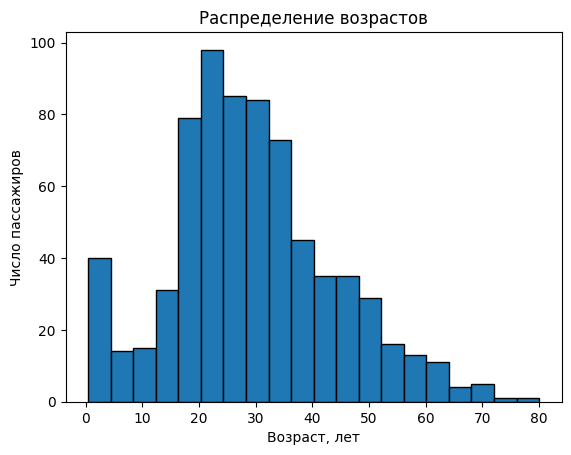

In [24]:
import matplotlib.pyplot as plt

plt.hist(df['Age'].dropna(), bins=20, edgecolor='black')
plt.xlabel('Возраст, лет')
plt.ylabel('Число пассажиров')
plt.title('Распределение возрастов')
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

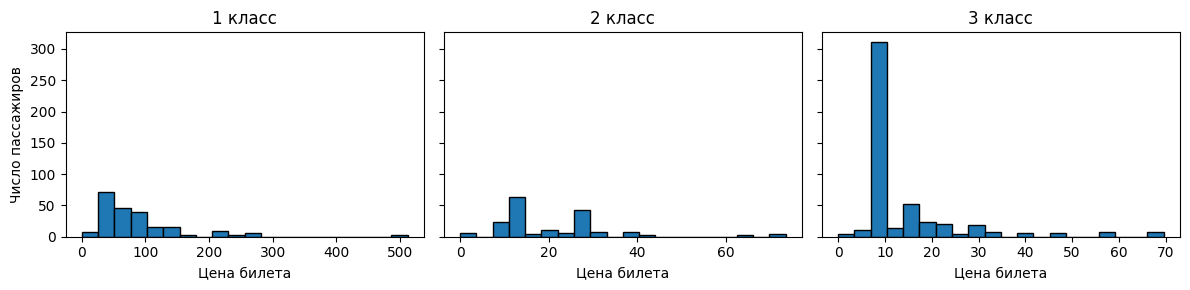

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, passenger_class in zip(axes, [1, 2, 3]):
    ax.hist(df.loc[df['Pclass'] == passenger_class, 'Fare'], bins=20, edgecolor='black')
    ax.set_title(f'{passenger_class} класс')
    ax.set_xlabel('Цена билета')
axes[0].set_ylabel('Число пассажиров')
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

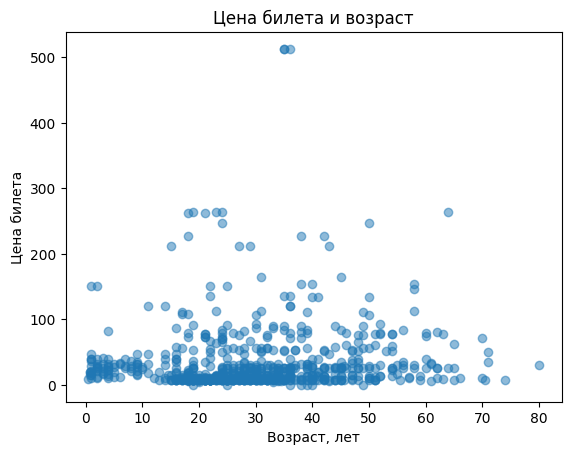

In [26]:
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.xlabel('Возраст, лет')
plt.ylabel('Цена билета')
plt.title('Цена билета и возраст')
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

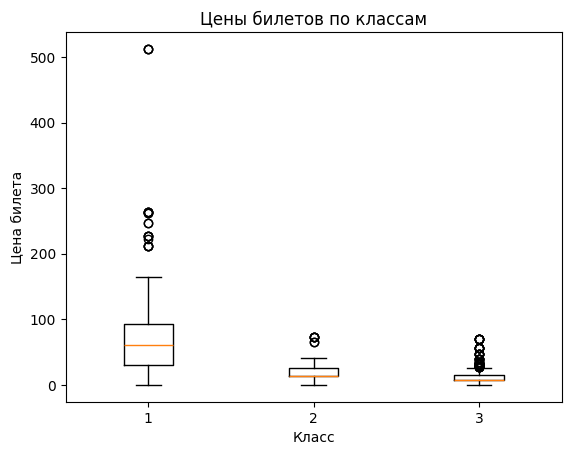

In [27]:
fares = [df.loc[df['Pclass'] == passenger_class, 'Fare'] for passenger_class in [1, 2, 3]]
plt.boxplot(fares, tick_labels=['1', '2', '3'])
plt.xlabel('Класс')
plt.ylabel('Цена билета')
plt.title('Цены билетов по классам')
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

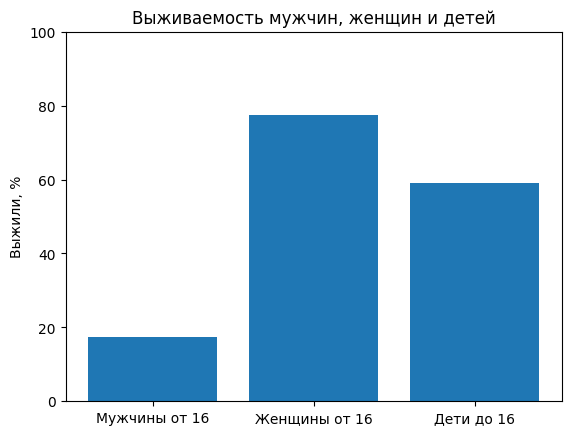

In [28]:
groups = ['Мужчины от 16', 'Женщины от 16', 'Дети до 16']
survival = [adult_men['Survived'].mean() * 100,
            adult_women['Survived'].mean() * 100,
            known_age.loc[child, 'Survived'].mean() * 100]
plt.bar(groups, survival)
plt.ylabel('Выжили, %')
plt.ylim(0, 100)
plt.title('Выживаемость мужчин, женщин и детей')
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

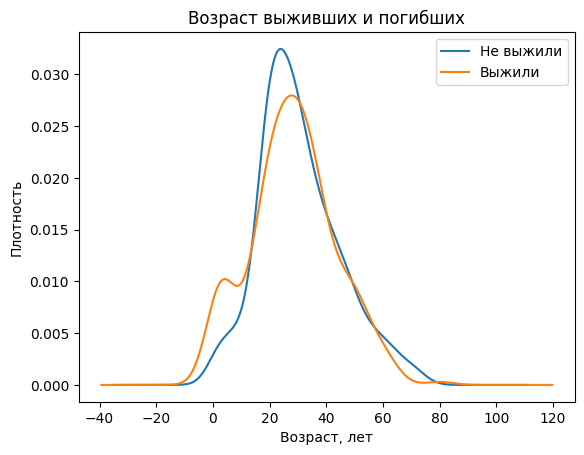

Среди выживших заметнее доля детей; основные пики обеих групп приходятся на взрослых.


In [29]:
for survived, label in [(0, 'Не выжили'), (1, 'Выжили')]:
    df.loc[df['Survived'] == survived, 'Age'].dropna().plot.kde(label=label)
plt.xlabel('Возраст, лет')
plt.ylabel('Плотность')
plt.title('Возраст выживших и погибших')
plt.legend()
plt.show()
print('Среди выживших заметнее доля детей; основные пики обеих групп приходятся на взрослых.')

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

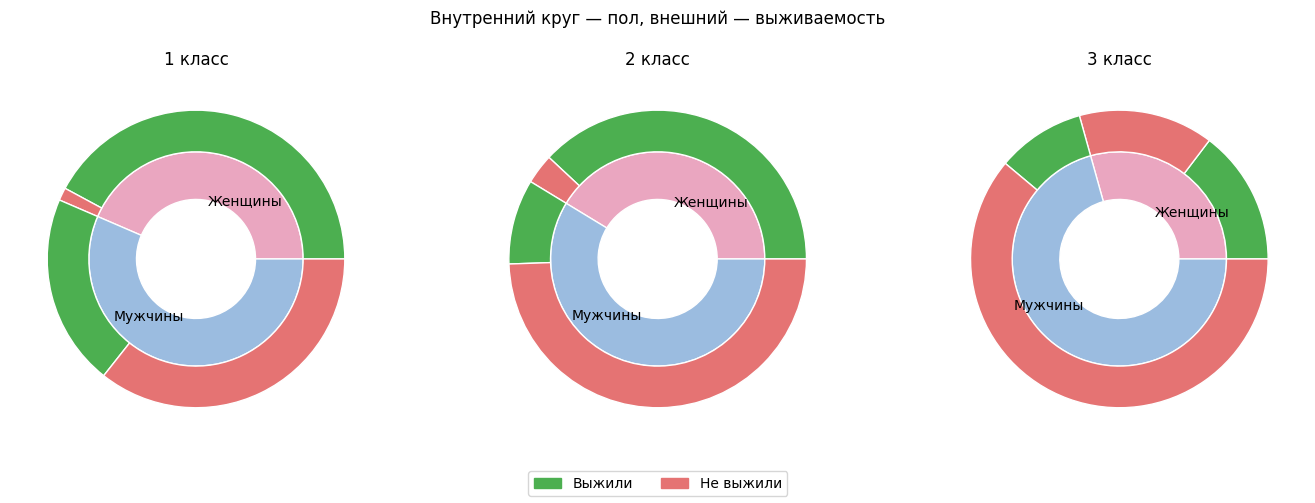

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, passenger_class in zip(axes, [1, 2, 3]):
    part = df[df['Pclass'] == passenger_class]
    women = part[part['Sex'] == 'female']
    men = part[part['Sex'] == 'male']
    inner = [len(women), len(men)]
    outer = [(women['Survived'] == 1).sum(), (women['Survived'] == 0).sum(),
             (men['Survived'] == 1).sum(), (men['Survived'] == 0).sum()]
    ax.pie(inner, radius=0.72, labels=['Женщины', 'Мужчины'],
           colors=['#eaa6c0', '#9bbce0'], labeldistance=0.55,
           wedgeprops={'width': 0.32, 'edgecolor': 'white'})
    ax.pie(outer, radius=1, colors=['#4caf50', '#e57373'] * 2,
           wedgeprops={'width': 0.28, 'edgecolor': 'white'})
    ax.set_title(f'{passenger_class} класс')
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#4caf50'),
                    plt.Rectangle((0, 0), 1, 1, color='#e57373')],
           labels=['Выжили', 'Не выжили'], loc='lower center', ncol=2)
fig.suptitle('Внутренний круг — пол, внешний — выживаемость')
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()